# Section 5. NumPy와 SciPy를 이용한 수치계산

**학습 순서:** 배열과 broadcasting → 난수·선형대수 → 함수·람다 → 적분·보간·근 찾기 → 제어문 → 옵션 가격격자.

**커널 재시작 → 모두 실행**으로 위에서부터 실행하세요. 다른 섹션의 변수나 함수가 필요하지 않습니다.
아래 셀의 실제 실행 결과가 저장되어 있습니다. 강의록에 실린 예시 출력은 별도의 Markdown으로 구분합니다.
배열과 가격·금리에는 `dtype=float`, `100.0`처럼 실수형을 사용합니다.

설치 명령, 함수 내부의 일부만 발췌한 코드, 끝나지 않는 반복문은 설명 셀에 보관했습니다.
의도적인 배열 조건문 오류는 `ValueError`를 잡아 메시지를 출력하므로 전체 실행을 중단시키지 않습니다.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
print("Section 5: NumPy/SciPy 실습을 시작합니다.")

Section 5: NumPy/SciPy 실습을 시작합니다.


## Python, NumPy와 SciPy의 역할

### 코드 예제 1

강의록 앞부분의 배열 예제도 바로 실행할 수 있도록 첫 셀에서 NumPy를 불러왔습니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 78행 · 예제 1</small>

In [2]:
values = np.array([100.0, 101.0, 102.0], dtype=float)
print(values, values.dtype)

[100. 101. 102.] float64


## 실습 Notebook과 라이브러리 준비하기

### 코드 예제 2



<small>강의록: `section05_numpy_scipy_functions.tex`, 103행 · 예제 2</small>

**필요할 때 한 번만 설치합니다.** 패키지가 준비되어 있다면 생략합니다. 새 코드 셀에 복사하여 실행한 뒤 커널을 재시작하세요.

```python
%pip install numpy scipy
```

### 이번 장에서 사용할 라이브러리 불러오기

현재 선택한 커널에서 사용하는 NumPy와 SciPy 버전을 확인합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 110행 · 예제 3</small>

In [3]:
import numpy as np
import scipy

from scipy.integrate import quad
from scipy.interpolate import PchipInterpolator
from scipy.optimize import brentq
from scipy.stats import norm

print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)

NumPy version: 2.3.5
SciPy version: 1.17.0


## NumPy 배열의 기본

### 리스트와 NumPy 배열의 곱셈 비교

리스트의 `* 2`는 원소 반복, NumPy 배열의 `* 2.0`은 원소별 곱셈입니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 142행 · 예제 4</small>

In [4]:
python_list = [1.0, 2.0, 3.0]

double_list = python_list * 2
print(double_list)

numpy_array = np.array([1.0, 2.0, 3.0], dtype=float)

double_array = numpy_array * 2.0
print(double_array)

[1.0, 2.0, 3.0, 1.0, 2.0, 3.0]
[2. 4. 6.]


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
[1.0, 2.0, 3.0, 1.0, 2.0, 3.0]
[2. 4. 6.]
```

### 1차원과 2차원 배열 만들기

`ndarray`는 규칙적인 수치배열입니다. 행과 열의 개수는 `shape`로 확인합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 174행 · 예제 6</small>

In [5]:
strike_prices = np.array([80.0, 90.0, 100.0, 110.0, 120.0], dtype=float)

scenario_matrix = np.array(
    [
        [95.0, 100.0, 105.0],
        [90.0, 100.0, 110.0],
    ],
    dtype=float,
)

print(strike_prices)
print(scenario_matrix)

[ 80.  90. 100. 110. 120.]
[[ 95. 100. 105.]
 [ 90. 100. 110.]]


### 가치평가용 격자와 초기 배열 만들기

격자와 초기값을 한 번에 만듭니다. `eye()`는 단위행렬입니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 210행 · 예제 7</small>

In [6]:
spot_grid = np.linspace(60.0, 140.0, num=9)
option_values = np.zeros(spot_grid.shape, dtype=float)
notional_values = np.full(5, 1_000_000.0, dtype=float)
identity_matrix = np.eye(3, dtype=float)
print("spot_grid:", spot_grid)
print("option_values:", option_values)
print("notional_values:", notional_values)
print("identity_matrix:\n", identity_matrix)

spot_grid: [ 60.  70.  80.  90. 100. 110. 120. 130. 140.]
option_values: [0. 0. 0. 0. 0. 0. 0. 0. 0.]
notional_values: [1000000. 1000000. 1000000. 1000000. 1000000.]
identity_matrix:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


### 배열의 기본 속성 확인하기

차원의 수, 각 차원의 길이, 전체 원소 수, 원소 자료형을 구분하세요.

<small>강의록: `section05_numpy_scipy_functions.tex`, 226행 · 예제 8</small>

In [7]:
print("ndim:", scenario_matrix.ndim)
print("shape:", scenario_matrix.shape)
print("size:", scenario_matrix.size)
print("dtype:", scenario_matrix.dtype)

ndim: 2
shape: (2, 3)
size: 6
dtype: float64


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
ndim: 2
shape: (2, 3)
size: 6
dtype: float64
```

### 코드 예제 10



<small>강의록: `section05_numpy_scipy_functions.tex`, 265행 · 예제 10</small>

In [8]:
print(values.shape)
print(values.dtype)

(3,)
float64


### 배열의 원소, 행과 열 선택하기

인덱스는 0부터 시작합니다. `:`는 해당 축의 모든 원소를 뜻합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 278행 · 예제 11</small>

In [9]:
prices = np.array(
    [
        [10.0, 12.0, 14.0],
        [11.0, 13.0, 15.0],
    ],
    dtype=float,
)

print(prices[0, 1])
print(prices[0, :])
print(prices[:, 1])
print(prices[:, :2])

12.0
[10. 12. 14.]
[12. 13.]
[[10. 12.]
 [11. 13.]]


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
12.0
[10. 12. 14.]
[12. 13.]
[[10. 12.]
 [11. 13.]]
```

### view를 수정하면 원본도 바뀌는 예

기본 슬라이스는 원본 메모리를 공유하는 view이므로 슬라이스 수정이 원본에도 반영됩니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 317행 · 예제 13</small>

In [10]:
spot_values = np.array([80.0, 90.0, 100.0, 110.0], dtype=float)

first_two = spot_values[:2]
first_two[0] = 999.0

print(first_two)
print(spot_values)

[999.  90.]
[999.  90. 100. 110.]


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
[999.  90.]
[999.  90. 100. 110.]
```

### 코드 예제 15

`copy()`로 독립 배열을 만들면 수정해도 원본이 바뀌지 않습니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 336행 · 예제 15</small>

In [11]:
first_two_copy = spot_values[:2].copy()
first_two_copy[0] = 80.0
print("copy:", first_two_copy)
print("original:", spot_values)

copy: [80. 90.]
original: [999.  90. 100. 110.]


## 배열 전체에 계산 적용하기

### 할인계수와 옵션 payoff의 벡터화 계산

$e^{-rT}$와 $(S_T-K)^+$를 배열 전체에 계산합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 355행 · 예제 16</small>

In [12]:
maturities = np.array([0.25, 0.5, 1.0, 2.0], dtype=float)
risk_free_rate = 0.03

discount_factors = np.exp(-risk_free_rate * maturities)

terminal_prices = np.array([80.0, 100.0, 120.0], dtype=float)
strike = 100.0
call_payoffs = np.maximum(terminal_prices - strike, 0.0)

print(discount_factors)
print(call_payoffs)

[0.99252805 0.98511194 0.97044553 0.94176453]
[ 0.  0. 20.]


### axis에 따른 평균 계산

`axis=0`은 행 방향을 줄이고, `axis=1`은 열 방향을 줄입니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 400행 · 예제 17</small>

In [13]:
path_values = np.array(
    [
        [10.0, 12.0, 14.0],
        [11.0, 13.0, 15.0],
    ],
    dtype=float,
)

mean_by_maturity = np.mean(path_values, axis=0)
mean_by_path = np.mean(path_values, axis=1)

print(mean_by_maturity)
print(mean_by_path)

[10.5 12.5 14.5]
[12. 13.]


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
[10.5 12.5 14.5]
[12. 13.]
```

### 불리언 마스크로 in-the-money 시나리오 선택하기

조건의 결과는 불리언 배열입니다. 이 배열을 인덱스로 사용하여 원하는 시나리오만 선택합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 443행 · 예제 19</small>

In [14]:
terminal_prices = np.array([80.0, 95.0, 100.0, 110.0, 125.0], dtype=float)
strike = 100.0

in_the_money = terminal_prices > strike
selected_prices = terminal_prices[in_the_money]

print(in_the_money)
print(selected_prices)

[False False False  True  True]
[110. 125.]


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
[False False False  True  True]
[110. 125.]
```

### np.where로 디지털 옵션 payoff 만들기

조건이 참인 곳에는 10.0, 거짓인 곳에는 0.0을 배치합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 465행 · 예제 21</small>

In [15]:
cash_payoff = 10.0
digital_payoff = np.where(terminal_prices > strike, cash_payoff, 0.0)

print(digital_payoff)

[ 0.  0.  0. 10. 10.]


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
[ 0.  0.  0. 10. 10.]
```

### 코드 예제 23

`all()`은 모든 원소, `any()`는 하나 이상의 원소에 대해 조건이 참인지 판단합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 481행 · 예제 23</small>

In [16]:
print(np.all(terminal_prices > 0.0))
print(np.any(terminal_prices > 120.0))

True
True


### 잘못된 배열 조건문

배열에는 여러 참/거짓 값이 있으므로 `if`가 한 가지로 결정할 수 없습니다. 원래 오류를 실제로 발생시킨 뒤 메시지만 출력합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 492행 · 예제 24</small>

In [17]:
try:
    if terminal_prices > strike:
        print("In the money")
except ValueError as error:
    print(f"의도한 오류: {type(error).__name__}: {error}")

의도한 오류: ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()


### 1차원 배열을 열벡터로 바꾸기

길이 3인 1차원 배열 `(3,)`과 열벡터 `(3, 1)`은 다른 모양입니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 508행 · 예제 25</small>

In [18]:
terminal_prices = np.array([80.0, 100.0, 120.0], dtype=float)
terminal_column = terminal_prices.reshape(3, 1)

print(terminal_prices.shape)
print(terminal_column.shape)

(3,)
(3, 1)


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
(3,)
(3, 1)
```

### 여러 기초자산 가격과 행사가격의 payoff 격자

열벡터와 행벡터를 결합하면 모든 가격·행사가격 조합을 한꺼번에 계산합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 528행 · 예제 27</small>

In [19]:
terminal_prices = np.array([80.0, 100.0, 120.0], dtype=float).reshape(3, 1)
strike_prices = np.array([90.0, 100.0, 110.0], dtype=float).reshape(1, 3)

call_payoff_grid = np.maximum(terminal_prices - strike_prices, 0.0)

print(call_payoff_grid.shape)
print(call_payoff_grid)

(3, 3)
[[ 0.  0.  0.]
 [10.  0.  0.]
 [30. 20. 10.]]


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
(3, 3)
[[ 0.  0.  0.]
 [10.  0.  0.]
 [30. 20. 10.]]
```

### 반복문과 벡터화 계산 비교

두 구현의 결과가 같은지 `np.allclose()`로 비교합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 567행 · 예제 29</small>

In [20]:
maturities = np.array([0.25, 0.5, 1.0, 2.0], dtype=float)
risk_free_rate = 0.03

loop_result = np.empty_like(maturities)

for index, maturity in enumerate(maturities):
    loop_result[index] = np.exp(-risk_free_rate * maturity)

vectorized_result = np.exp(-risk_free_rate * maturities)

print(np.allclose(loop_result, vectorized_result))

True


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
True
```

## 난수와 간단한 몬테카를로 계산

### 표준정규 난수 생성하기

시드를 고정하면 동일한 실행 환경에서 같은 난수 표본을 재현할 수 있습니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 600행 · 예제 31</small>

In [21]:
rng = np.random.default_rng(seed=2026)
standard_normals = rng.standard_normal(size=100_000)

print(standard_normals.shape)
print(standard_normals.dtype)

(100000,)
float64


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
(100000,)
float64
```

### 벡터화된 몬테카를로 콜옵션 가격

위험중립측도 $\mathbb{Q}$에서 GBM의 만기가격을 직접 생성하고, 할인 payoff의 평균으로 콜 가격을 추정합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 622행 · 예제 33</small>

In [22]:
number_of_paths = 100_000

spot = 100.0
strike = 100.0
maturity = 1.0
risk_free_rate = 0.03
dividend_yield = 0.0
volatility = 0.20

rng = np.random.default_rng(seed=2026)
z = rng.standard_normal(size=number_of_paths)

drift = risk_free_rate - dividend_yield - 0.5 * volatility**2
terminal_prices = spot * np.exp(drift * maturity + volatility * np.sqrt(maturity) * z)

discount_factor_value = np.exp(-risk_free_rate * maturity)
payoffs = np.maximum(terminal_prices - strike, 0.0)
discounted_payoffs = discount_factor_value * payoffs
monte_carlo_price = np.mean(discounted_payoffs)

print(f"MC price: {monte_carlo_price:.6f}")

MC price: 9.389657


## 행렬계산의 대표 함수

### 선형방정식으로 복제 포트폴리오 구하기

현금과 주식 보유량을 구해 두 상태의 목표 payoff를 복제합니다. `@`는 행렬곱입니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 677행 · 예제 34</small>

In [23]:
payoff_matrix = np.array(
    [
        [1.0, 80.0],
        [1.0, 120.0],
    ],
    dtype=float,
)

target_payoff = np.array([0.0, 20.0], dtype=float)
holdings = np.linalg.solve(payoff_matrix, target_payoff)
replicated_payoff = payoff_matrix @ holdings

print("holdings:", holdings)
print("check:", replicated_payoff)
print(np.allclose(replicated_payoff, target_payoff))

holdings: [-40.    0.5]
check: [ 0. 20.]
True


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
holdings: [-40.    0.5]
check: [ 0. 20.]
True
```

## 사용자 정의 함수

### 할인계수 함수 만들기

입력과 반환값을 함수 내부에서 `float`로 변환합니다. 타입 주석만으로 자동 변환되지는 않습니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 718행 · 예제 36</small>

In [24]:
def discount_factor(rate: float, maturity: float) -> float:
    """Continuously compounded discount factor."""

    rate = float(rate)
    maturity = float(maturity)

    if maturity < 0.0:
        raise ValueError("maturity must be nonnegative")

    value = np.exp(-rate * maturity)
    return float(value)


result = discount_factor(rate=0.03, maturity=2.0)
print(result)

0.9417645335842487


### 함수 설명 확인하기

`help()`는 함수의 인자와 문서 문자열을 보여 줍니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 746행 · 예제 37</small>

In [25]:
help(discount_factor)

Help on function discount_factor in module __main__:

discount_factor(rate: float, maturity: float) -> float
    Continuously compounded discount factor.



### 코드 예제 38



<small>강의록: `section05_numpy_scipy_functions.tex`, 756행 · 예제 38</small>

**함수 본문에서 발췌한 설명용 코드입니다.** `return`은 함수 안에 있어야 하므로 독립 셀에서 실행하지 않습니다. 위 `discount_factor()`가 완성된 실행 예제입니다.

```python
rate = float(rate)
return float(value)
```

### 기본 매개변수를 가진 선도가격 함수

기본 인자를 두면 배당이 없을 때는 `dividend_yield`를 생략할 수 있습니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 779행 · 예제 39</small>

In [26]:
def forward_price(
    spot: float,
    maturity: float,
    rate: float,
    dividend_yield: float = 0.0,
) -> float:
    spot = float(spot)
    maturity = float(maturity)
    rate = float(rate)
    dividend_yield = float(dividend_yield)

    value = spot * np.exp((rate - dividend_yield) * maturity)
    return float(value)


price_without_dividend = forward_price(spot=100.0, maturity=1.0, rate=0.03)

price_with_dividend = forward_price(
    spot=100.0,
    maturity=1.0,
    rate=0.03,
    dividend_yield=0.01,
)
print("without dividend:", price_without_dividend)
print("with dividend:", price_with_dividend)

without dividend: 103.0454533953517
with dividend: 102.02013400267558


### 콜과 풋 payoff를 계산하는 사용자 정의 함수

스칼라와 배열을 `np.asarray()`로 통일하여 같은 payoff 함수를 재사용합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 817행 · 예제 40</small>

In [27]:
def option_payoff(terminal_price, strike: float, option_type: str):
    terminal_price = np.asarray(terminal_price, dtype=float)
    strike = float(strike)

    if strike <= 0.0:
        raise ValueError("strike must be positive")

    if option_type == "call":
        return np.maximum(terminal_price - strike, 0.0)
    if option_type == "put":
        return np.maximum(strike - terminal_price, 0.0)

    raise ValueError("option_type must be call or put")


terminal_prices = np.array([80.0, 100.0, 120.0], dtype=float)
print(option_payoff(terminal_prices, strike=100.0, option_type="call"))

[ 0.  0. 20.]


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
[ 0.  0. 20.]
```

## 람다 함수

### 일반 함수와 람다 함수 비교

간단한 한 줄 함수는 `lambda`로 표현할 수 있습니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 869행 · 예제 42</small>

In [28]:
def square_function(x):
    return x**2


square_lambda = lambda x: x**2

print(square_function(3.0))
print(square_lambda(3.0))

9.0
9.0


### 할인된 연속 현금흐름 적분에 사용할 람다 함수

적분 변수 time을 입력받아 할인계수를 반환하는 함수를 준비합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 883행 · 예제 43</small>

In [29]:
risk_free_rate = 0.04
integrand = lambda time: np.exp(-risk_free_rate * time)

## SciPy의 대표 기능

### 표준정규분포의 대표 함수

`pdf`는 밀도, `cdf`는 누적확률, `ppf`는 분위수입니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 921행 · 예제 44</small>

In [30]:
x = np.array([-1.0, 0.0, 1.0], dtype=float)

print("pdf:", norm.pdf(x))
print("cdf:", norm.cdf(x))
print("97.5% quantile:", norm.ppf(0.975))

pdf: [0.24197072 0.39894228 0.24197072]
cdf: [0.15865525 0.5        0.84134475]
97.5% quantile: 1.959963984540054


### 스칼라와 배열을 받는 Black–Scholes 콜옵션 함수

Black–Scholes 콜 가격함수입니다. 배열 입력의 모양이 broadcasting 규칙을 만족하면 여러 계약을 함께 평가합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 946행 · 예제 45</small>

In [31]:
def black_scholes_call_price(
    spot,
    strike,
    maturity,
    rate,
    volatility,
    dividend_yield=0.0,
):
    spot = np.asarray(spot, dtype=float)
    strike = np.asarray(strike, dtype=float)
    maturity = np.asarray(maturity, dtype=float)
    rate = np.asarray(rate, dtype=float)
    volatility = np.asarray(volatility, dtype=float)
    dividend_yield = np.asarray(dividend_yield, dtype=float)

    if np.any(spot <= 0.0):
        raise ValueError("spot must be positive")
    if np.any(strike <= 0.0):
        raise ValueError("strike must be positive")
    if np.any(maturity <= 0.0):
        raise ValueError("maturity must be positive")
    if np.any(volatility <= 0.0):
        raise ValueError("volatility must be positive")

    sqrt_maturity = np.sqrt(maturity)
    log_moneyness = np.log(spot / strike)
    drift = rate - dividend_yield + 0.5 * volatility**2
    d1 = (log_moneyness + drift * maturity) / (volatility * sqrt_maturity)
    d2 = d1 - volatility * sqrt_maturity

    discounted_spot = spot * np.exp(-dividend_yield * maturity)
    discounted_strike = strike * np.exp(-rate * maturity)
    price = discounted_spot * norm.cdf(d1) - discounted_strike * norm.cdf(d2)

    return price

### Black–Scholes 함수 사용하기

한 계약의 가격과 세 행사가격의 가격배열을 비교하세요.

<small>강의록: `section05_numpy_scipy_functions.tex`, 986행 · 예제 46</small>

In [32]:
scalar_price = black_scholes_call_price(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    volatility=0.20,
)

strike_array = np.array([90.0, 100.0, 110.0], dtype=float)

array_prices = black_scholes_call_price(
    spot=100.0,
    strike=strike_array,
    maturity=1.0,
    rate=0.03,
    volatility=0.20,
)

print(float(scalar_price))
print(array_prices)
print(array_prices.dtype)

9.413403383853016
[15.42922724  9.41340338  5.29339806]
float64


### 연속 현금흐름의 현재가치 계수 적분

수치적분 결과를 해석식과 비교합니다. 적분기가 보고하는 추정오차도 함께 확인합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1035행 · 예제 47</small>

In [33]:
risk_free_rate = 0.04
maturity = 5.0

integrand = lambda time: np.exp(-risk_free_rate * time)
annuity_factor, error_estimate = quad(integrand, 0.0, maturity)
analytic_value = (1.0 - np.exp(-risk_free_rate * maturity)) / risk_free_rate

print(annuity_factor)
print(error_estimate)
print(analytic_value)
print(np.isclose(annuity_factor, analytic_value))

4.531731173050453
5.031232289732182e-14
4.531731173050455
True


### 할인계수 곡선 보간하기

시장 만기 사이의 할인계수를 PCHIP로 보간합니다. `extrapolate=False`이므로 주어진 구간 밖은 외삽하지 않습니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1070행 · 예제 48</small>

In [34]:
market_maturities = np.array([0.25, 0.5, 1.0, 2.0, 5.0], dtype=float)
zero_rates = np.array([0.032, 0.033, 0.034, 0.036, 0.038], dtype=float)
market_discount_factors = np.exp(-zero_rates * market_maturities)

discount_curve = PchipInterpolator(market_maturities, market_discount_factors, extrapolate=False)

target_maturities = np.linspace(0.25, 5.0, num=20)
interpolated_discount_factors = discount_curve(target_maturities)

print(float(discount_curve(1.5)))

0.9486062647237673


**보충 그림:** 원래 만기의 할인계수와 보간곡선을 함께 표시합니다.

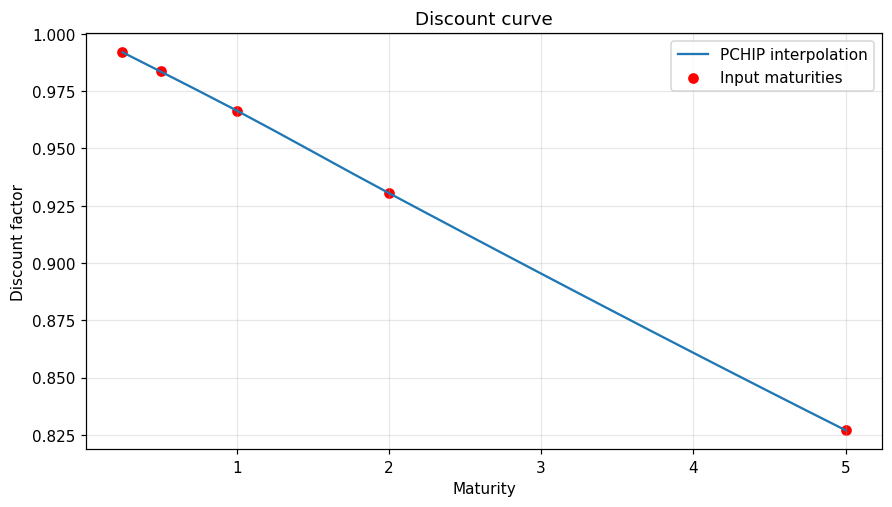

In [35]:
fig, ax = plt.subplots(figsize=(8.0, 4.5), layout="constrained")
ax.plot(target_maturities, interpolated_discount_factors, label="PCHIP interpolation")
ax.scatter(market_maturities, market_discount_factors, color="red", label="Input maturities")
ax.set(title="Discount curve", xlabel="Maturity", ylabel="Discount factor")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### Black–Scholes implied volatility 계산하기

모형가격 − 시장가격을 0으로 만드는 변동성을 찾습니다. `brentq()`를 호출하기 전에 구간 양 끝의 부호를 확인합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1117행 · 예제 49</small>

In [36]:
market_price = 9.413403383853016

objective = lambda sigma: float(
    black_scholes_call_price(
        spot=100.0,
        strike=100.0,
        maturity=1.0,
        rate=0.03,
        volatility=sigma,
    ) - market_price
)

lower_bound = 1.0e-6
upper_bound = 3.0

print(objective(lower_bound))
print(objective(upper_bound))

implied_volatility = brentq(
    objective,
    lower_bound,
    upper_bound,
    xtol=1.0e-12,
)

print(implied_volatility)

-6.457956738703835
77.42451534112155
0.19999999999999982


## 제어문을 가치평가 코드에 사용하기

### 옵션 종류에 따라 payoff 공식 선택하기

선택한 옵션 종류에 따라 서로 다른 payoff 공식을 적용합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1186행 · 예제 50</small>

In [37]:
option_type = "call"
terminal_price = 115.0
strike = 100.0

if option_type == "call":
    payoff = max(terminal_price - strike, 0.0)
elif option_type == "put":
    payoff = max(strike - terminal_price, 0.0)
else:
    raise ValueError("option_type must be call or put")

print(payoff)

15.0


### 만기별 할인계수 출력하기

반복문의 인덱스와 값을 동시에 얻으려면 `enumerate()`를 사용합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1210행 · 예제 51</small>

In [38]:
maturities = np.array([0.25, 0.5, 1.0, 2.0], dtype=float)

for index, maturity in enumerate(maturities, start=1):
    value = discount_factor(rate=0.03, maturity=maturity)
    print(f"{index}: T={maturity:.2f}, DF={value:.6f}")

1: T=0.25, DF=0.992528
2: T=0.50, DF=0.985112
3: T=1.00, DF=0.970446
4: T=2.00, DF=0.941765


### 실수의 정확한 일치를 기다리는 잘못된 while문



<small>강의록: `section05_numpy_scipy_functions.tex`, 1233행 · 예제 52</small>

**실행하지 않는 오류 예제입니다.** 0.1을 반복해서 더해도 이진 부동소수점 표현 때문에 정확히 1.0이 되지 않아 반복이 끝나지 않습니다.

```python
value = 0.0

while value != 1.0:
    value += 0.1
```

**안전한 관찰용 코드:** 같은 계산을 최대 12번까지만 수행하여 정확한 등호가 성립하는지 확인합니다.

In [39]:
value = 0.0
for step in range(1, 13):
    value += 0.1
    print(f"{step:2d}: {value!r}, value == 1.0: {value == 1.0}")

 1: 0.1, value == 1.0: False
 2: 0.2, value == 1.0: False
 3: 0.30000000000000004, value == 1.0: False
 4: 0.4, value == 1.0: False
 5: 0.5, value == 1.0: False
 6: 0.6, value == 1.0: False
 7: 0.7, value == 1.0: False
 8: 0.7999999999999999, value == 1.0: False
 9: 0.8999999999999999, value == 1.0: False
10: 0.9999999999999999, value == 1.0: False
11: 1.0999999999999999, value == 1.0: False
12: 1.2, value == 1.0: False


### 고정된 반복횟수와 허용오차 사용하기

반복횟수가 정해져 있으면 `for`를 사용하고, 실수의 비교에는 허용오차를 둡니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1244행 · 예제 53</small>

In [40]:
value = 0.0

for _ in range(10):
    value += 0.1

print(value)
print(np.isclose(value, 1.0))

0.9999999999999999
True


**강의록에 제시된 예시 출력** — 위 실행 결과와 비교하세요.

```text
0.9999999999999999
True
```

### 배리어 도달 시 break로 반복 중단하기

가격이 배리어 이하로 처음 내려가는 인덱스에서 반복을 중단합니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1270행 · 예제 55</small>

In [41]:
price_path = np.array([100.0, 103.0, 101.0, 97.0, 93.0, 90.0, 88.0], dtype=float)

barrier = 92.0
step = 0
knocked_out = False

while step < price_path.size:
    current_price = price_path[step]

    if current_price <= barrier:
        knocked_out = True
        print("Barrier reached at step", step)
        break

    step += 1

if not knocked_out:
    print("Barrier was not reached")

Barrier reached at step 5


## 종합 예제: 옵션 가격 격자 만들기

### 행사가격과 만기에 따른 옵션 가격 격자

행은 만기, 열은 행사가격인 가격격자를 만듭니다. 아래에는 같은 격자를 시각화하는 보충 코드도 붙였습니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1314행 · 예제 56</small>

In [42]:
strike_values = np.linspace(80.0, 120.0, num=9)
maturity_values = np.array([0.25, 0.5, 1.0, 2.0], dtype=float)
strike_grid, maturity_grid = np.meshgrid(strike_values, maturity_values)

price_grid = black_scholes_call_price(
    spot=100.0,
    strike=strike_grid,
    maturity=maturity_grid,
    rate=0.03,
    volatility=0.20,
)

print("strike grid:", strike_grid.shape)
print("maturity grid:", maturity_grid.shape)
print("price grid:", price_grid.shape)
print("dtype:", price_grid.dtype)

strike grid: (4, 9)
maturity grid: (4, 9)
price grid: (4, 9)
dtype: float64


**보충 그림:** 계산한 가격격자를 3차원으로 표시합니다.

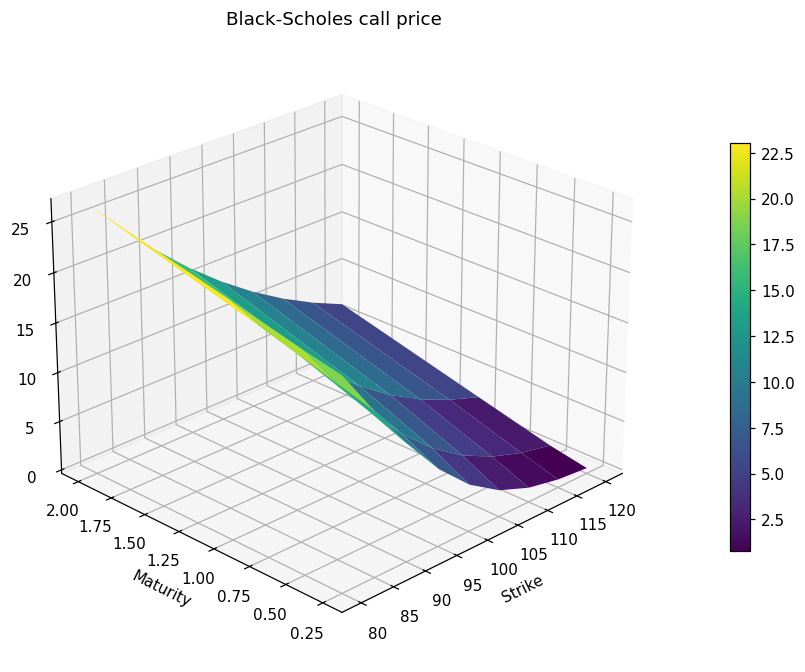

In [43]:
fig = plt.figure(figsize=(9.0, 6.0), layout="constrained")
ax = fig.add_subplot(111, projection="3d")
surface = ax.plot_surface(strike_grid, maturity_grid, price_grid, cmap="viridis")
ax.set(title="Black-Scholes call price", xlabel="Strike", ylabel="Maturity", zlabel="Call price")
ax.view_init(elev=25.0, azim=-135.0)
fig.colorbar(surface, ax=ax, shrink=0.65, pad=0.10)
plt.show()

## 직접 해보기

### 코드 예제 57

연습 1의 입력 리스트입니다. 뒤의 참고 풀이에서 실수형 배열로 바꿉니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1409행 · 예제 57</small>

In [44]:
maturities = [0.25, 0.5, 1.0, 2.0]
volatilities = [0.15, 0.20, 0.25]

### 코드 예제 58

연습 2에서 사용할 기초자산 만기가격입니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1421행 · 예제 58</small>

In [45]:
[80.0, 100.0, 120.0, 140.0]

[80.0, 100.0, 120.0, 140.0]

### 코드 예제 59

연습 2에서 사용할 행사가격입니다.

<small>강의록: `section05_numpy_scipy_functions.tex`, 1427행 · 예제 59</small>

In [46]:
[90.0, 100.0, 110.0]

[90.0, 100.0, 110.0]

## 연습문제 참고 풀이

먼저 직접 작성한 뒤 비교하세요. 아래는 원고의 연습문제를 완성한 **추가 코드**입니다.

### 연습 1. 배열의 shape와 dtype

In [47]:
maturities = np.array([0.25, 0.5, 1.0, 2.0], dtype=float)
volatilities = np.array([0.15, 0.20, 0.25], dtype=float)
for name, values in [("maturities", maturities), ("volatilities", volatilities)]:
    print(name, "shape:", values.shape, "ndim:", values.ndim, "size:", values.size, "dtype:", values.dtype)

maturities shape: (4,) ndim: 1 size: 4 dtype: float64
volatilities shape: (3,) ndim: 1 size: 3 dtype: float64


### 연습 2. payoff 격자

In [48]:
terminal_prices = np.array([80.0, 100.0, 120.0, 140.0], dtype=float).reshape(4, 1)
strike_prices = np.array([90.0, 100.0, 110.0], dtype=float).reshape(1, 3)
payoff_grid = np.maximum(terminal_prices - strike_prices, 0.0)
print("shape:", payoff_grid.shape)
print(payoff_grid)
assert payoff_grid.shape == (4, 3)

shape: (4, 3)
[[ 0.  0.  0.]
 [10.  0.  0.]
 [30. 20. 10.]
 [50. 40. 30.]]


### 연습 3. 사용자 정의 함수

정수 입력도 함수 안에서 실수로 변환합니다. 잘못된 입력이 거절되는지도 확인합니다.

In [49]:
def bond_price(face_value, yield_rate, maturity):
    face_value = float(face_value)
    yield_rate = float(yield_rate)
    maturity = float(maturity)
    if face_value <= 0.0 or maturity < 0.0:
        raise ValueError("face_value must be positive and maturity must be nonnegative")
    return float(face_value * np.exp(-yield_rate * maturity))

bond_value = bond_price(100, 0.03, 2)
print("price:", bond_value, "type:", type(bond_value))
try:
    bond_price(-100.0, 0.03, 2.0)
except ValueError as error:
    print("의도한 입력검사:", error)

price: 94.17645335842487 type: <class 'float'>
의도한 입력검사: face_value must be positive and maturity must be nonnegative


### 연습 4. implied volatility

In [50]:
exercise_market_price = 12.0
objective_exercise = lambda sigma: float(black_scholes_call_price(100.0, 100.0, 1.0, 0.03, sigma) - exercise_market_price)
lower_bound, upper_bound = 1.0e-6, 3.0
print("Endpoint values:", objective_exercise(lower_bound), objective_exercise(upper_bound))
exercise_iv = brentq(objective_exercise, lower_bound, upper_bound, xtol=1.0e-12)
print(f"Implied volatility: {exercise_iv:.8f}")
print("Repriced call:", float(black_scholes_call_price(100.0, 100.0, 1.0, 0.03, exercise_iv)))

Endpoint values: -9.04455335485082 74.83791872497457
Implied volatility: 0.26683024
Repriced call: 11.999999999999993


### 연습 5. 상단 배리어 확인

배리어 도달과 미도달의 두 경우를 모두 실행합니다.

In [51]:
def first_upper_barrier_hit(price_path, barrier):
    price_path = np.asarray(price_path, dtype=float)
    barrier = float(barrier)
    step = 0
    while step < price_path.size:
        if price_path[step] >= barrier:
            break
        step += 1
    if step < price_path.size:
        print("Barrier reached at index", step)
        return step
    print("Barrier was not reached")
    return None

first_upper_barrier_hit([100.0, 103.0, 106.0, 104.0], 105.0)
first_upper_barrier_hit([100.0, 103.0, 104.0, 102.0], 105.0)

Barrier reached at index 2
Barrier was not reached


### 연습 6. 옵션 가격 표면 준비

price grid: (12, 31) float64


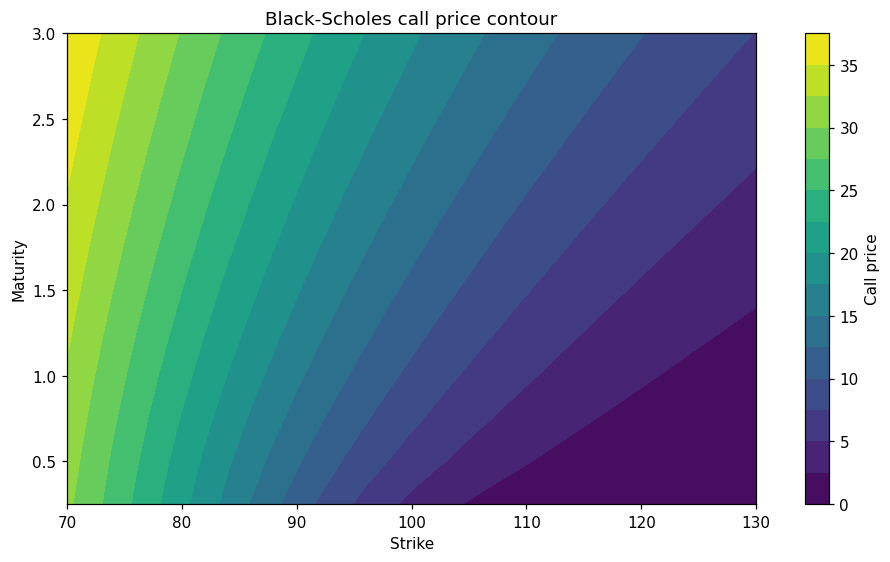

In [52]:
strikes_exercise = np.linspace(70.0, 130.0, num=31)
maturities_exercise = np.linspace(0.25, 3.0, num=12)
strike_grid_exercise, maturity_grid_exercise = np.meshgrid(strikes_exercise, maturities_exercise)
price_grid_exercise = black_scholes_call_price(100.0, strike_grid_exercise, maturity_grid_exercise, 0.03, 0.20)
print("price grid:", price_grid_exercise.shape, price_grid_exercise.dtype)

fig, ax = plt.subplots(figsize=(8.0, 5.0), layout="constrained")
contour = ax.contourf(strike_grid_exercise, maturity_grid_exercise, price_grid_exercise, levels=15, cmap="viridis")
ax.set(title="Black-Scholes call price contour", xlabel="Strike", ylabel="Maturity")
fig.colorbar(contour, ax=ax, label="Call price")
plt.show()

## 마무리 확인

- 리스트와 배열의 곱셈, view와 copy를 구분할 수 있나요?
- `shape`를 먼저 확인하고 broadcasting을 적용했나요?
- 여러 불리언 값을 `if`에 직접 넣지 않고 목적에 맞게 `all`·`any`·마스크를 사용했나요?
- 수치적분과 implied volatility 결과를 기준식 또는 재계산으로 검산했나요?
- 실수의 반복계산에서 정확한 등호 대신 반복횟수·허용오차를 사용했나요?

**원고와의 실행상 차이:** NumPy를 첫 셀에서 먼저 불러왔고, 결과가 보이도록 일부 출력문을 추가했습니다.
설명용 발췌·설치·무한반복 코드는 Markdown으로 보관했습니다. 배열 조건문의 `ValueError`는 출력 후 다음 셀로 진행합니다.
보간·가격격자 그림과 연습문제 참고 풀이는 보충 코드입니다.